In [1]:
# importing libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from hh_sim import hh_sim

Homework 1, problem 4c

In [2]:
# variables
R = 1.0
tau_m = 10.0
tau_s = 2.0
u_rest = 0.0
u_th = 1.0

r = tau_s / tau_m
t_peak = (tau_m * tau_s / (tau_s - tau_m)) * np.log(tau_s / tau_m)
u_max = r ** (-1 / (r - 1))
I_crit = u_th / (R * u_max)

In [3]:
def lif_equation(t, u, I_0, tau_s):
    I_t = I_0 * np.exp(-t / tau_s)
    du_dt = (-u[0] + R * I_t) / tau_m
    return [du_dt]

t_eval = np.linspace(0, 50, 10001)
amplitudes = {
    "below": 0.8 * I_crit,
    "critical": I_crit,
    "above": 1.2 * I_crit
}

In [4]:
results = []
solutions = {}

for label, I_0 in amplitudes.items():
    
    solution = solve_ivp(lif_equation, 
                         [0, 50], 
                         [u_rest], 
                         t_eval = 
                         t_eval, 
                         args = (I_0, tau_s))
    
    u = solution.y[0]
    
    peak_index = np.argmax(u)
    numerical_peak = u[peak_index]
    numerical_tpeak = solution.t[peak_index]

    results.append([
        label,
        I_0,
        numerical_tpeak,
        numerical_peak
    ])

    solutions[label] = (solution.t, u)

In [5]:
print("\nNumerical results")
print(f"{'Amplitude':<15} {'I0 (mA)':>12} {'t_peak (ms)':>15} {'u_peak (mV)':>15}")
print("-" * 60)

for label, I0, tp, up in results:
    print(f"{label:<15} {I0:>12.4f} {tp:>15.4f} {up:>15.4f}")



Numerical results
Amplitude            I0 (mA)     t_peak (ms)     u_peak (mV)
------------------------------------------------------------
below                 5.9814          4.0350          0.7999
critical              7.4767          4.0350          0.9998
above                 8.9721          4.0350          1.1998


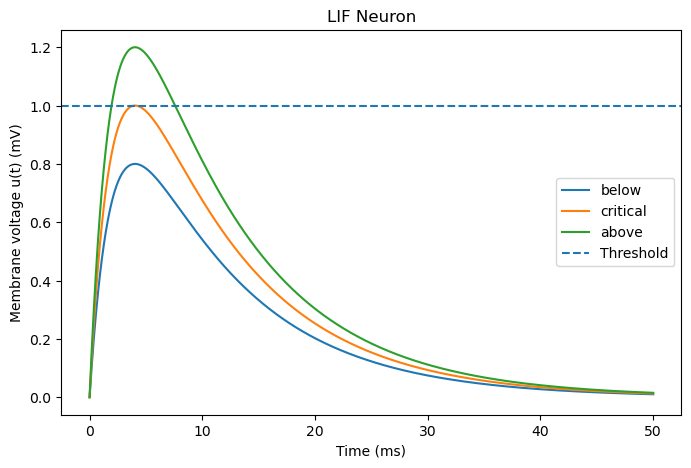

In [6]:
plt.figure(figsize=(8, 5))

for label, (t, u) in solutions.items():
    plt.plot(t, u, label=label)

plt.axhline(u_th, linestyle = "--", label = "Threshold")

plt.xlabel("Time (ms)")
plt.ylabel("Membrane voltage u(t) (mV)")
plt.title("LIF Neuron")
plt.legend()
plt.show()

In [7]:
tau_s_values = np.logspace(
    np.log10(0.5),
    np.log10(100),
    500
)

I_crit_values = []

for ts in tau_s_values:

    r = ts / tau_m

    if np.isclose(r, 1.0): # when tau_s = tau_m
        # limit r -> 1 gives exp(-1)
        peak_factor = np.exp(-1)
    else:
        peak_factor = r ** (-1 / (r - 1))

    I_crit = u_th / (R * peak_factor)
    I_crit_values.append(I_crit)

I_crit_values = np.array(I_crit_values)

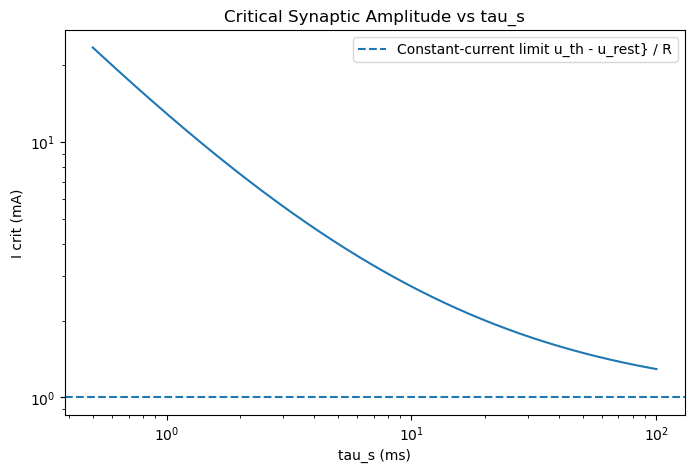

In [8]:
plt.figure(figsize = (8, 5))

plt.loglog(tau_s_values, I_crit_values)

# Constant-current limit
plt.axhline(
    u_th / R,
    linestyle = "--",
    label = "Constant-current limit u_th - u_rest} / R"
)

plt.xlabel("tau_s (ms)")
plt.ylabel("I crit (mA)")
plt.title("Critical Synaptic Amplitude vs tau_s")
plt.legend()
plt.show()

Homework 1, problem 5

In [9]:
TMAX = 300.0
SKIPFRAC = 0.4
MIN_SPIKES = 3

def is_repetitive(Id, gK = 36):
    t, V, spk, rate = hh_sim(Id = Id,
                             tmax = TMAX,
                             gK = gK,
                             skipfrac = SKIPFRAC)
    return len(spk) >= MIN_SPIKES

def find_rheobase(gK = 36, low = 0, high = 15, tol = 0.0005):
    
    if is_repetitive(low, gK):
        raise ValueError("Lower bound already fires repetitively")
        
    if not is_repetitive(high, gK):
        raise ValueError("Upper bound does not fire repetitively")
        
    while high - low > tol:
        mid = (low + high) / 2
        
        if is_repetitive(mid, gK):
            high = mid
        else:
            low = mid
            
    return (low + high) / 2

Rheobase (gK = 36): 6.258 uA/cm^2
Criterion: at least 3 spikes after discarding the first 40% of the trace.


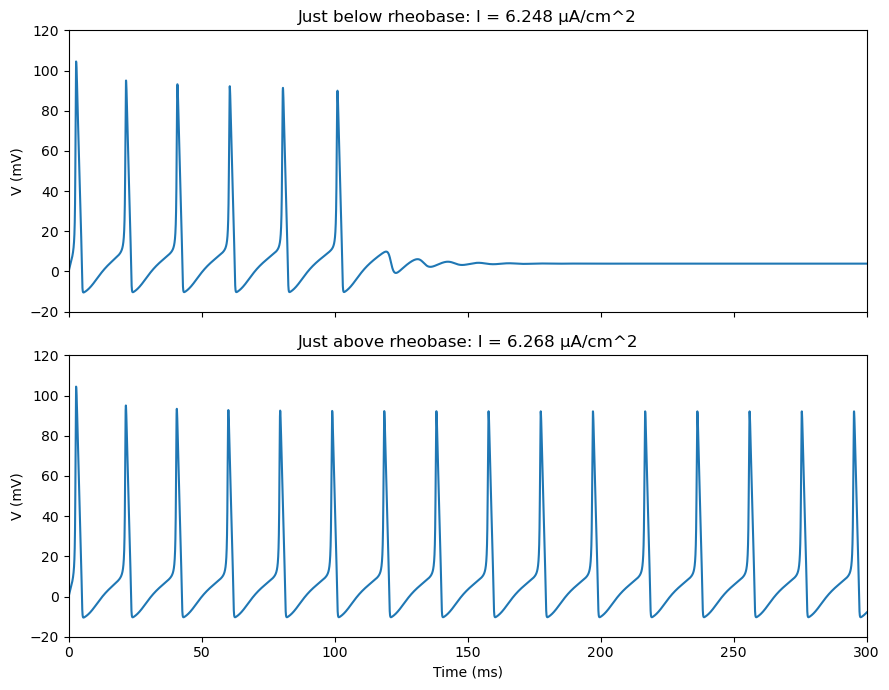

In [10]:
# part a

rheo_36 = find_rheobase(gK = 36)

print(f"Rheobase (gK = 36): {rheo_36:.3f} uA/cm^2")
print(
    f"Criterion: at least {MIN_SPIKES} spikes after discarding the first {SKIPFRAC * 100:.0f}% of the trace."
)

delta = 0.01

I_below = rheo_36 - delta
I_above = rheo_36 + delta

t1, V1, spk1, rate1 = hh_sim(
    Id=I_below,
    tmax=TMAX,
    gK=36,
    skipfrac=SKIPFRAC
)

t2, V2, spk2, rate2 = hh_sim(
    Id=I_above,
    tmax=TMAX,
    gK=36,
    skipfrac=SKIPFRAC
)

fig, ax = plt.subplots(2, 1, figsize=(9, 7), sharex=True, sharey=True)

ax[0].plot(t1, V1)
ax[0].set_title(
    f"Just below rheobase: I = {I_below:.3f} μA/cm^2"
)
ax[0].set_ylabel("V (mV)")

ax[1].plot(t2, V2)
ax[1].set_title(
    f"Just above rheobase: I = {I_above:.3f} μA/cm^2"
)
ax[1].set_xlabel("Time (ms)")
ax[1].set_ylabel("V (mV)")

ax[0].set_xlim(0, TMAX)
ax[1].set_xlim(0, TMAX)

ax[0].set_ylim(-20, 120)
ax[1].set_ylim(-20, 120)

plt.tight_layout()
plt.show()

Current just above rheobase: 6.259 uA/cm^2
Onset firing rate: 49.432 Hz


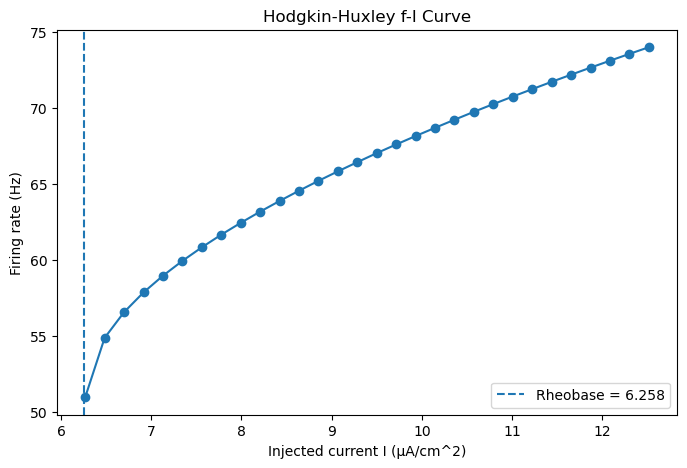

In [11]:
# part b

currents_36 = np.linspace(rheo_36 + 0.01,
                          2 * rheo_36,
                          30)
rates_36 = []

for Id in currents_36:
    t, V, spk, rate = hh_sim(Id = Id, 
                             tmax = TMAX,
                             gK = 36,
                             skipfrac = SKIPFRAC)
    rates_36.append(rate)
    
rates_36 = np.array(rates_36)

I_onset = rheo_36 + 0.001

t, V, spk, onset_rate = hh_sim(
    Id = I_onset,
    tmax = TMAX,
    gK = 36,
    skipfrac = SKIPFRAC)

print(f"Current just above rheobase: {I_onset:.3f} uA/cm^2")
print(f"Onset firing rate: {onset_rate:.3f} Hz")

plt.figure(figsize=(8, 5))

plt.plot(currents_36, rates_36, "o-")

plt.axvline(
    rheo_36,
    linestyle="--",
    label=f"Rheobase = {rheo_36:.3f}"
)

plt.xlabel("Injected current I (μA/cm^2)")
plt.ylabel("Firing rate (Hz)")
plt.title("Hodgkin-Huxley f-I Curve")
plt.legend()

plt.show()

In [12]:
# part c

rheo_30 = find_rheobase(gK = 30)

print(f"{'gK (mS/cm^2)':<18} {'Rheobase (uA/cm^2)':<20}")
print("-" * 38)
print(f"{36:<18.0f} {rheo_36:<20.3f}")
print(f"{30:<18.0f} {rheo_30:<20.3f}")

gK (mS/cm^2)       Rheobase (uA/cm^2)  
--------------------------------------
36                 6.258               
30                 2.774               


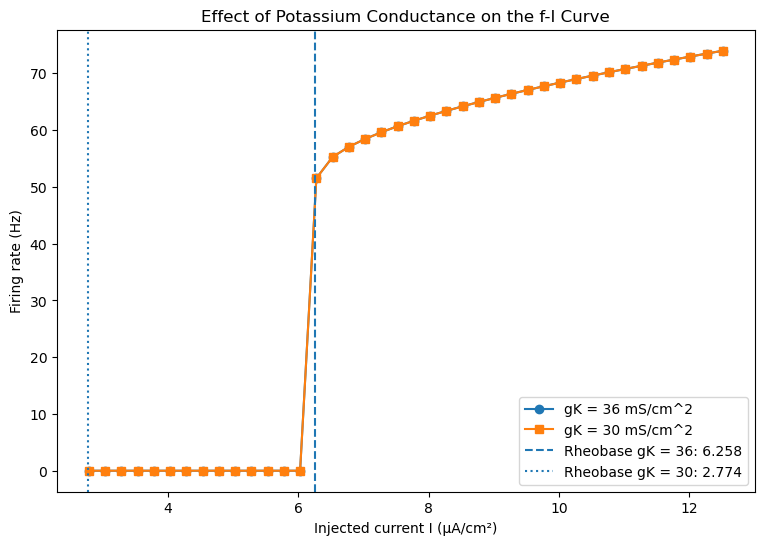

In [13]:
I_min = min(rheo_30, rheo_36) + 0.01
I_max = 2 * max(rheo_30, rheo_36)

currents = np.linspace(I_min, I_max, 40)

rates_36_overlay = []
rates_30_overlay = []

for Id in currents:

    # gK = 36
    t, V, spk, rate = hh_sim(Id = Id,
                            tmax = TMAX,
                            gK = 36,
                            skipfrac = SKIPFRAC)

    if len(spk) >= MIN_SPIKES:
        rates_36_overlay.append(rate)
    else:
        rates_36_overlay.append(0)

    t, V, spk, rate = hh_sim(Id = Id,
                            tmax = TMAX,
                            gK = 36,
                            skipfrac = SKIPFRAC)
    

    if len(spk) >= MIN_SPIKES:
        rates_30_overlay.append(rate)
    else:
        rates_30_overlay.append(0)

rates_36_overlay = np.array(rates_36_overlay)
rates_30_overlay = np.array(rates_30_overlay)

plt.figure(figsize=(9, 6))

plt.plot(
    currents,
    rates_36_overlay,
    "o-",
    label = "gK = 36 mS/cm^2"
)

plt.plot(
    currents,
    rates_30_overlay,
    "s-",
    label = "gK = 30 mS/cm^2"
)

# Mark rheobases
plt.axvline(
    rheo_36,
    linestyle = "--",
    label = f"Rheobase gK = 36: {rheo_36:.3f}"
)

plt.axvline(
    rheo_30,
    linestyle = ":",
    label = f"Rheobase gK = 30: {rheo_30:.3f}"
)

plt.xlabel("Injected current I (μA/cm²)")
plt.ylabel("Firing rate (Hz)")
plt.title("Effect of Potassium Conductance on the f-I Curve")

plt.legend()
plt.show()